In [1]:
import base
import os    
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'

import numpy as np
import matplotlib.pyplot as plt
#from tqdm import tqdm_notebook as tqdm
from tqdm.auto import tqdm
import torch
import time

#from data.gbm import GBM
import tensor_algebra as ta
import iisignature
import lqproblem_fbm_tracking as lqproblem
from fbm import FBM
import optimiser_lqproblem_fast as optimiser_lqproblem
from math import factorial
import pickle
from differint.differint import RL

C:\Users\User\anaconda3\Lib\site-packages\torch\__init__.py:1275: UserWarning: torch.set_default_tensor_type() is deprecated as of PyTorch 2.1, please use torch.set_default_dtype() and torch.set_default_device() as alternatives. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\tensor\python_tensor.cpp:436.)
  _C._set_default_tensor_type(t)


In [2]:
import matplotlib.pylab as pylab
params = {'legend.fontsize': 'x-large',
          'figure.figsize': (15, 5),
         'axes.labelsize': 'x-large',
         'axes.titlesize':'x-large',
         'xtick.labelsize':'x-large',
         'ytick.labelsize':'x-large'}
pylab.rcParams.update(params)
%config InlineBackend.figure_format = "retina"

import matplotlib
plt.rc('text', usetex=True)
plt.rc('text.latex', preamble=r'\usepackage{amsmath,amsfonts}')

In [5]:
with open(f'experiment_params_fbm_new.pkl', 'rb') as f:
    params = pickle.load(f)
    f.close()

env = lqproblem.environment(**params)
env_optimal = lqproblem.environment(**params)

In [6]:
params

{'b0': 0,
 'b1': 1,
 'b2': 1,
 'sigma0': 1,
 'sigma2': 0,
 'X0': 0,
 'A': 1,
 'B': 1,
 'C': 0,
 'D': 0,
 'E': 0,
 'G': 0,
 'T': 1,
 'Nt': 1000,
 'hurst_inv': 4}

In [7]:
max_order_x_list = [1, 2, 3, 4, 5]
# max_order_x_list = [2, 3, 4, 5]
max_order_F_list = [0, 1, 2, 3]
nsims = 10000
dim = env.dim
nsims_small = nsims
nsim = 0 

with open(f'experiment_results_fbm_optimal_{nsims}_sims.pkl', 'rb') as f:
    sim_optimal = pickle.load(f)
    f.close()

In [8]:
# sim_list = [sim for sim in sim_list if sim['max_order_x'] in max_order_x_list]

In [9]:
# plt.plot(env.timesteps, nu_hjb[:,nsim], label=r'$\nu$ (HJB)', color='black')

# for max_order_x in max_order_x_list:
#     for max_order_F in max_order_F_list:
#         nu = [sims['nu_sims'] for sims in sim_list if (sims['max_order_x'] == max_order_x) and (sims['max_order_F'] == max_order_F)][0]
#         plt.plot(env.timesteps, nu[:,nsim], label=rf'$\nu$ (sig-method, state_trunc = {max_order_x}, contr_trunc = {max_order_F})',
#                          alpha=0.5)
#         # if max_order_x >= 4 and max_order_F >= 2:
#         #         nu = [sims['nu_sims'] for sims in sim_list if (sims['max_order_x'] == max_order_x) and (sims['max_order_F'] == max_order_F)][0]
#         #         plt.plot(env.timesteps, nu[:,nsim], label=rf'$\nu$ (sig-method, state_trunc = {max_order_x}, contr_trunc = {max_order_F})',
#         #                  alpha=0.5)

# plt.legend()
# plt.tight_layout()
# plt.show()

In [10]:
sim_optimal

{'nu_sims': array([[-0.00000000e+00, -0.00000000e+00, -0.00000000e+00, ...,
         -0.00000000e+00, -0.00000000e+00, -0.00000000e+00],
        [ 5.07854661e-02,  2.06225220e-01,  1.47818080e-01, ...,
         -1.25288661e-01, -2.09606877e-02, -3.25302389e-01],
        [-5.87896296e-02,  1.44254094e-01,  4.35276927e-02, ...,
         -1.05837172e-01,  4.95270985e-02, -2.98130136e-01],
        ...,
        [-4.24069565e-04,  5.81174961e-04,  6.97293015e-04, ...,
          1.41895075e-03,  2.36774124e-03,  3.46044900e-03],
        [-4.41109428e-05,  4.08206941e-04,  3.96412569e-04, ...,
          5.04224556e-04,  1.12277815e-03,  1.47045013e-03],
        [-4.41109428e-05,  4.08206941e-04,  3.96412569e-04, ...,
          5.04224556e-04,  1.12277815e-03,  1.47045013e-03]]),
 'W_H': array([[ 0.        ,  0.        ,  0.        , ...,  0.        ,
          0.        ,  0.        ],
        [-0.03008461, -0.12216498, -0.0875654 , ...,  0.07421928,
          0.01241682,  0.19270466],
       

In [13]:
perform

[np.float64(1.4291495959354839)]

In [14]:
sim_list

[{'max_order_x': 1,
  'max_order_F': 3,
  'W_H': array([[ 0.        ,  0.        ,  0.        , ...,  0.        ,
           0.        ,  0.        ],
         [-0.03008461, -0.12216498, -0.0875654 , ...,  0.07421928,
           0.01241682,  0.19270466],
         [ 0.0867739 , -0.05637633,  0.02348806, ...,  0.05367246,
          -0.06277616,  0.16425772],
         ...,
         [ 0.14817092, -0.19974393, -0.35274371, ..., -0.86109814,
          -1.00952492, -1.05193684],
         [-0.03223101, -0.31687475, -0.39635656, ..., -0.62207389,
          -0.96325581, -0.78464118],
         [-0.19341859, -0.35383873, -0.45497943, ..., -0.75549562,
          -0.86883305, -0.96026505]]),
  'X': array([[ 0.        ,  0.        ,  0.        , ...,  0.        ,
           0.        ,  0.        ],
         [-0.03006693, -0.12214731, -0.08754772, ...,  0.07423696,
           0.0124345 ,  0.19272234],
         [ 0.08677919, -0.05646312,  0.02343587, ...,  0.05378206,
          -0.06272836,  0.1644858

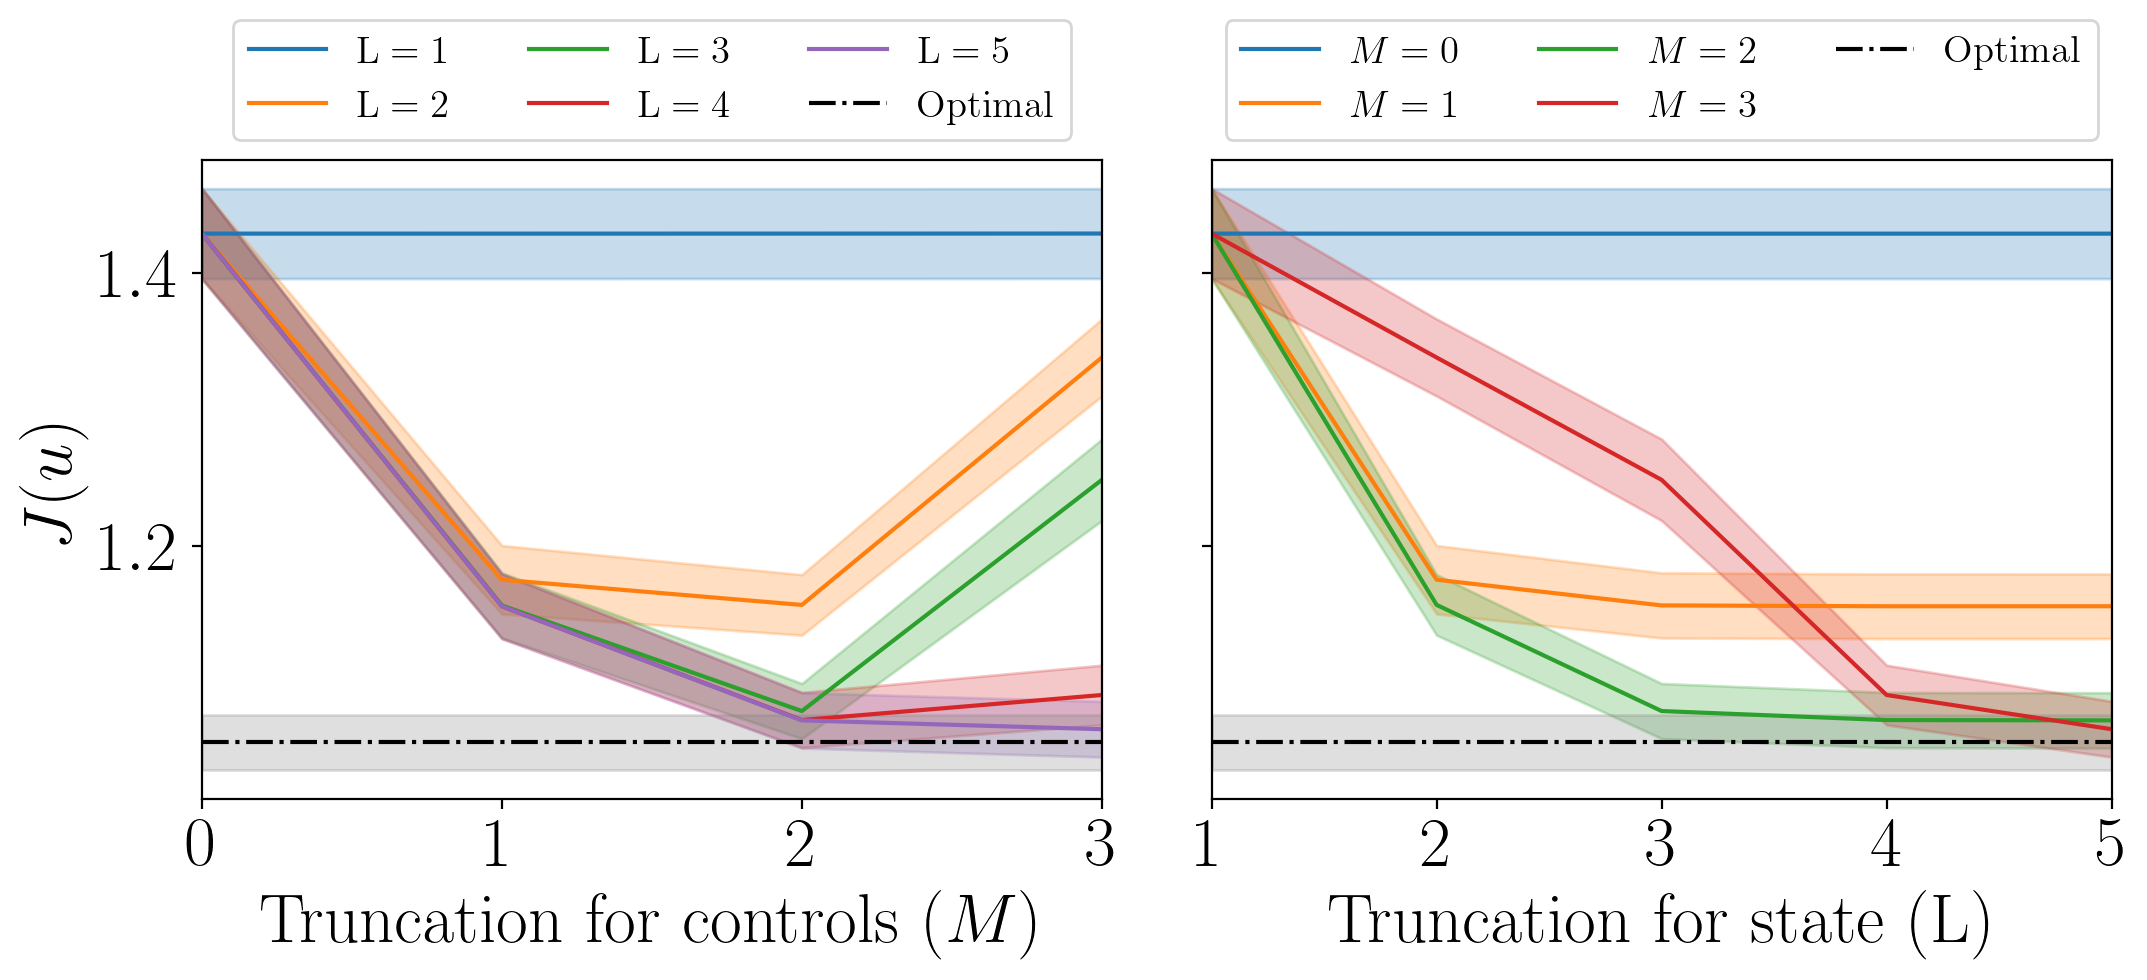

In [18]:
lev = 'L'

font1 = 25
font2 = 14

Z_val = 1.96

perform_optimal = sim_optimal['performance_mean']
perform_optimal_list = sim_optimal['performance_list']
perform_optimal_std = perform_optimal_list.std(ddof = 1)/np.sqrt(nsims)
perform_optimal_LCI = perform_optimal - Z_val*perform_optimal_std
perform_optimal_UCI = perform_optimal + Z_val*perform_optimal_std

fig, ax = plt.subplots(1, 2, figsize=(11,5), sharey='row')

sim_list = []
for n, max_order_x in enumerate(max_order_x_list):
    for max_order_F in max_order_F_list:
        with open(f'experiment_fbm_lev_control_{max_order_F}_lev_state_{max_order_x}_sims_{nsims}.pkl', 'rb') as f:
            sim = pickle.load(f)
            sim_list.append(sim)
            f.close()
    perform = [experiment['performance_list'].mean() for experiment in sim_list if experiment['max_order_x']==max_order_x]
    perform_list = np.array([experiment['performance_list'] for experiment in sim_list if experiment['max_order_x']==max_order_x])
    perform_std = perform_list.std(axis = 1, ddof = 1)/np.sqrt(nsims)
    perform_LCI = perform - Z_val*perform_std
    perform_UCI = perform + Z_val*perform_std
    ax[0].fill_between(max_order_F_list, perform_LCI, perform_UCI,alpha=0.25, color=f'C{n}')
    ax[0].plot(max_order_F_list, perform, label=rf'$\mathrm{{{lev}}} = {max_order_x}$', color=f'C{n}')
ax[0].set_xlabel(r'$\mathrm{Truncation}$ $\mathrm{for}$ $\mathrm{controls}$ $(M)$',  fontsize = font1)
ax[0].set_xticks(ticks=max_order_F_list)

for n, max_order_F in enumerate(max_order_F_list):
    # sim_list = []
    # for max_order_x in max_order_x_list:
    #     with open(f'experiment_fbm_lev_control_{max_order_F}_lev_state_{max_order_x}_sims_{nsims}.pkl', 'rb') as f:
    #         sim = pickle.load(f)
    #         sim_list.append(sim)
    #         f.close()
    perform = [experiment['performance_list'].mean() for experiment in sim_list if experiment['max_order_F']==max_order_F]
    perform_list = np.array([experiment['performance_list'] for experiment in sim_list if experiment['max_order_F']==max_order_F])
    perform_std = perform_list.std(axis = 1, ddof = 1)/np.sqrt(nsims)
    perform_LCI = perform - Z_val*perform_std
    perform_UCI = perform + Z_val*perform_std
    ax[1].fill_between(max_order_x_list, perform_LCI, perform_UCI,alpha=0.25, color=f'C{n}')
    ax[1].plot(max_order_x_list, perform, label=rf'$M = {max_order_F}$', color=f'C{n}')
ax[1].set_xlabel(rf'$\mathrm{{Truncation}}$ $\mathrm{{for}}$ $\mathrm{{state}}$ $(\mathrm{{{lev}}})$',  fontsize = font1)
ax[1].set_xticks(ticks=max_order_x_list)

ax[0].set_ylabel(f'$J(u)$',  fontsize = font1)

for ax_i in ax:
    ax_i.tick_params(axis='both', which='major', labelsize=font1)
    #ax_i.set_yscale('log')
    ax_i.fill_between(ax_i.get_xticks(), perform_optimal_LCI, perform_optimal_UCI,alpha=0.25, color='grey')
    ax_i.axhline(perform_optimal, color = 'black', linestyle='-.', label=r'$\mathrm{Optimal}$')
    ax_i.set_xlim(ax_i.get_xticks()[0], ax_i.get_xticks()[-1])

ax[0].legend(fontsize=font2, loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=3)
ax[1].legend(fontsize=font2, loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=3)
fig.tight_layout()
fig.savefig(f'figures/perform_diff_fbm.pdf',format='pdf',bbox_inches='tight')
plt.show()

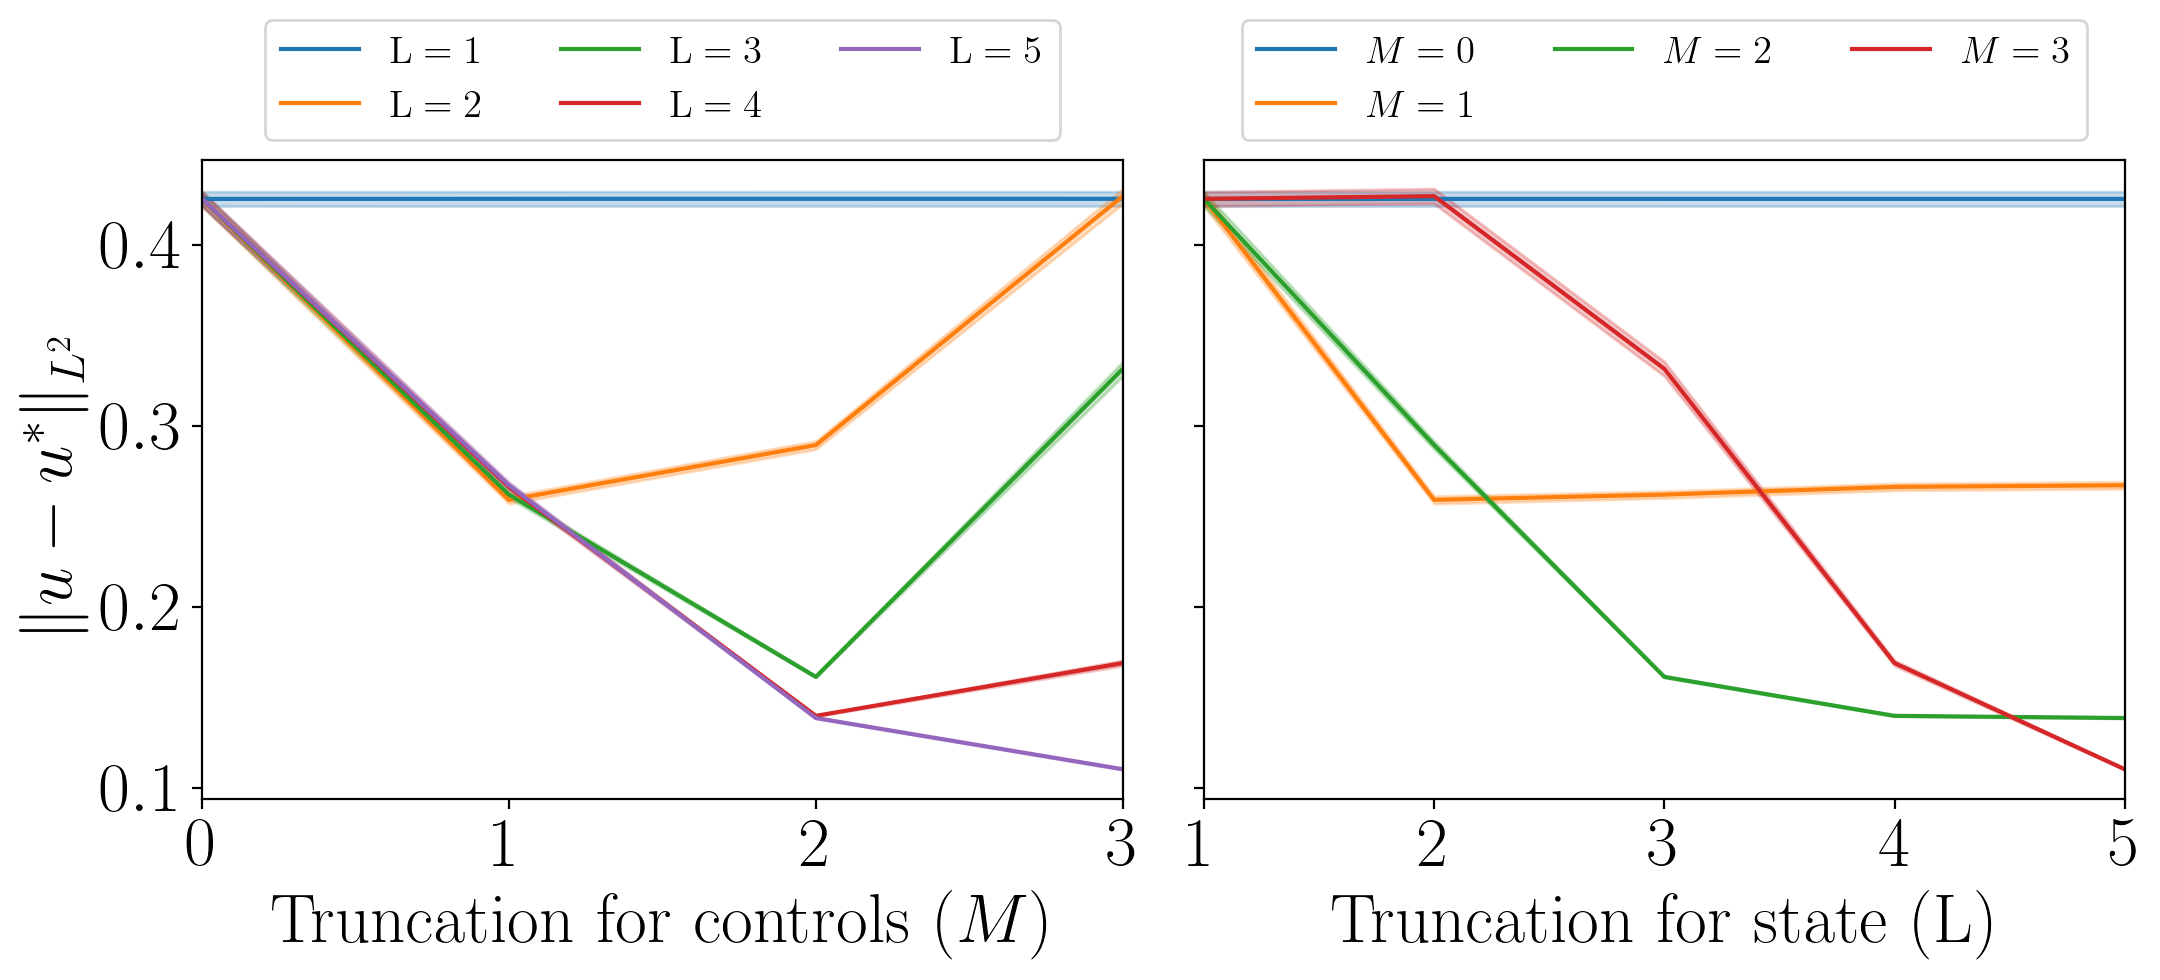

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(11,5), sharey='row')

for n, max_order_x in enumerate(max_order_x_list):
    nu_L2_dist = [(np.sqrt((((experiment['nu_sims'] - sim_optimal['nu_sims'])**2).sum(axis=0))*env.T/env.Nt)).mean() 
                  for experiment in sim_list if experiment['max_order_x']==max_order_x]
    nu_L2_dist_list = np.array([np.sqrt((((experiment['nu_sims'] - sim_optimal['nu_sims'])**2).sum(axis=0))*env.T/env.Nt) 
                                for experiment in sim_list if experiment['max_order_x']==max_order_x])
    nu_L2_dist_std = nu_L2_dist_list.std(axis = 1, ddof = 1)/np.sqrt(nsims)
    nu_L2_dist_LCI = nu_L2_dist - Z_val*nu_L2_dist_std
    nu_L2_dist_UCI = nu_L2_dist + Z_val*nu_L2_dist_std
    ax[0].fill_between(max_order_F_list, nu_L2_dist_LCI, nu_L2_dist_UCI,alpha=0.25, color=f'C{n}')
    ax[0].plot(max_order_F_list, nu_L2_dist, label=rf'$\mathrm{{{lev}}} = {max_order_x}$', color=f'C{n}')
ax[0].set_xlabel(r'$\mathrm{Truncation}$ $\mathrm{for}$ $\mathrm{controls}$ $(M)$',  fontsize = font1)
ax[0].set_xticks(ticks=max_order_F_list)

for n, max_order_F in enumerate(max_order_F_list):
    nu_L2_dist = [(np.sqrt((((experiment['nu_sims'] - sim_optimal['nu_sims'])**2).sum(axis=0))*env.T/env.Nt)).mean()
                   for experiment in sim_list if experiment['max_order_F']==max_order_F]
    nu_L2_dist_list = np.array([np.sqrt((((experiment['nu_sims'] - sim_optimal['nu_sims'])**2).sum(axis=0))*env.T/env.Nt) 
                                for experiment in sim_list if experiment['max_order_F']==max_order_F])
    nu_L2_dist_std = nu_L2_dist_list.std(axis = 1, ddof = 1)/np.sqrt(nsims)
    nu_L2_dist_LCI = nu_L2_dist - Z_val*nu_L2_dist_std
    nu_L2_dist_UCI = nu_L2_dist + Z_val*nu_L2_dist_std
    ax[1].fill_between(max_order_x_list, nu_L2_dist_LCI, nu_L2_dist_UCI,alpha=0.25, color=f'C{n}')
    ax[1].plot(max_order_x_list, nu_L2_dist, label=rf'$M = {max_order_F}$', color=f'C{n}')
ax[1].set_xlabel(rf'$\mathrm{{Truncation}}$ $\mathrm{{for}}$ $\mathrm{{state}}$ $(\mathrm{{{lev}}})$',  fontsize = font1)
ax[1].set_xticks(ticks=max_order_x_list)

ax[0].set_ylabel(r'$\|u - u^*\|_{L^2}$',  fontsize = font1)

for ax_i in ax:
    ax_i.tick_params(axis='both', which='major', labelsize=font1)
    ax_i.set_xlim(ax_i.get_xticks()[0], ax_i.get_xticks()[-1])

ax[0].legend(fontsize=font2, loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=3)
ax[1].legend(fontsize=font2, loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=3)
fig.tight_layout()
fig.savefig(f'figures/control_diff_fbm.pdf',format='pdf',bbox_inches='tight')
plt.show()

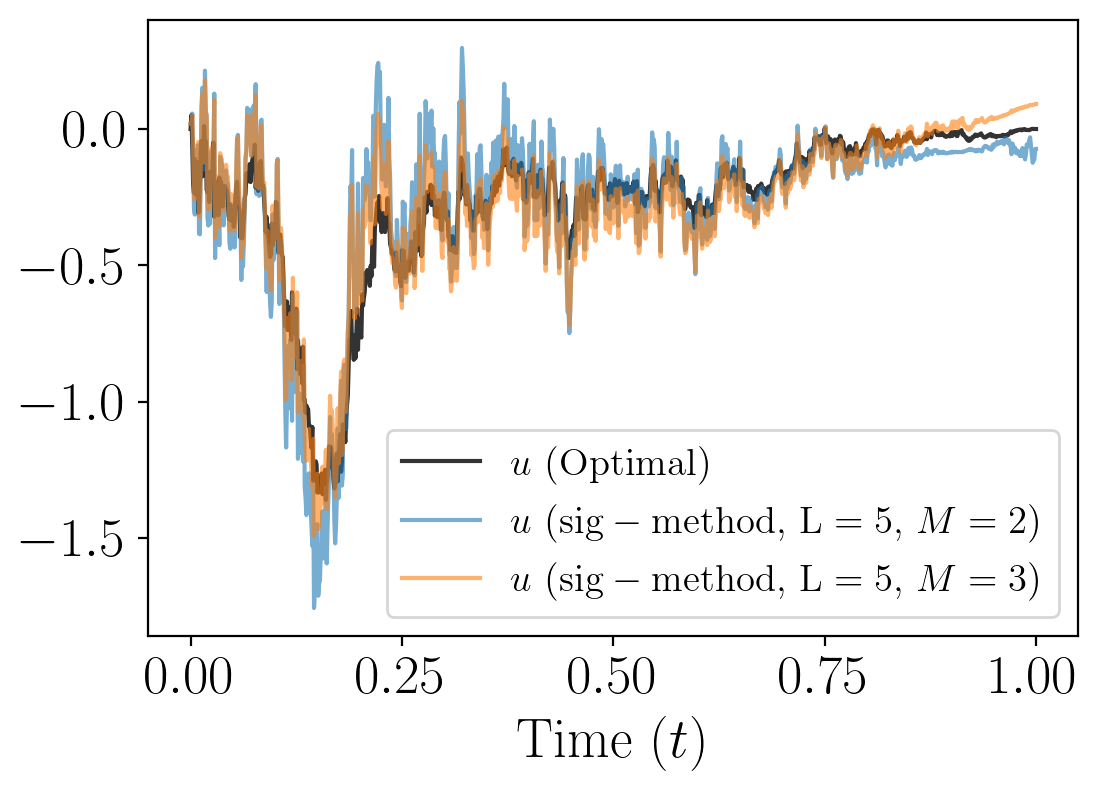

In [28]:
nsim = 0
font3 = 20
font4 = 14

fig, ax = plt.subplots(1, 1, figsize=(6,4))

max_order_x_1 = 5
max_order_F_1 = 2

max_order_x_2 = 5
max_order_F_2 = 3

nu_optimal = sim_optimal['nu_sims']
nu_1 = [sims['nu_sims'] for sims in sim_list if (sims['max_order_x'] == max_order_x_1) and (sims['max_order_F'] == max_order_F_1)][0]
nu_2 = [sims['nu_sims'] for sims in sim_list if (sims['max_order_x'] == max_order_x_2) and (sims['max_order_F'] == max_order_F_2)][0]

ax.plot(env.timesteps, nu_optimal[:,nsim], label=r'$u$ $\mathrm{(Optimal)}$', color='black', alpha = 0.8)
ax.plot(env.timesteps, nu_1[:,nsim], label=rf'$u$ $(\mathrm{{sig-method}},$ $\mathrm{{{lev}}} = {max_order_x_1},$ $M = {max_order_F_1})$',
        alpha=0.6)
ax.plot(env.timesteps, nu_2[:,nsim], label=rf'$u$ $(\mathrm{{sig-method}},$ $\mathrm{{{lev}}} = {max_order_x_2},$ $M = {max_order_F_2})$',
        alpha=0.6)

ax.set_xlabel(rf'$\mathrm{{Time}}$ $(t)$',  fontsize = font3)
ax.tick_params(axis='both', which='major', labelsize=font3)

ax.legend(fontsize=font4, loc='lower right')
fig.savefig(f'figures/control_sample_path_fbm.pdf',format='pdf',bbox_inches='tight')
plt.show()

In [20]:
for sim in sim_list:
    perf_diff = sim['performance_list'] - perform_optimal_list
    perf_diff_mean = perf_diff.mean()
    perf_diff_std = perf_diff.std(ddof = 1)/np.sqrt(nsims)
    perf_diff_LCI = perf_diff_mean - Z_val*perf_diff_std
    perf_diff_UCI = perf_diff_mean + Z_val*perf_diff_std
    print(f'{lev}:{sim['max_order_x']}, M:{sim['max_order_F']}')
    print(f'Mean difference: {perf_diff_mean}, std: {perf_diff_std}')

L:1, M:0
Mean difference: 0.3733314100171251, std: 0.006910927058273941
L:1, M:1
Mean difference: 0.37331895805219717, std: 0.006911275878568343
L:1, M:2
Mean difference: 0.37334547782510724, std: 0.006909556087556736
L:1, M:3
Mean difference: 0.37338475951389116, std: 0.006909216068161092
L:2, M:0
Mean difference: 0.3733111283399463, std: 0.00691251174417549
L:2, M:1
Mean difference: 0.11931970214435542, std: 0.002865845314847025
L:2, M:2
Mean difference: 0.10081493917604553, std: 0.001241677813149497
L:2, M:3
Mean difference: 0.28239672581497355, std: 0.004262747020773253
L:3, M:0
Mean difference: 0.3733103349291074, std: 0.006912897746739742
L:3, M:1
Mean difference: 0.100445491370088, std: 0.002227961817722765
L:3, M:2
Mean difference: 0.022914380942507646, std: 0.00032997611589328965
L:3, M:3
Mean difference: 0.1926101602826606, std: 0.005640171834467179
L:4, M:0
Mean difference: 0.37331032113007234, std: 0.006912958537327053
L:4, M:1
Mean difference: 0.09981511921490072, std: 0.0

In [24]:
for sim in sim_list:
    perf_diff = sim['performance_list'] - perform_optimal_list
    perf_diff_mean = perf_diff.mean()
    perf_diff_std = perf_diff.std(ddof = 1)/np.sqrt(nsims)
    perf_diff_LCI = perf_diff_mean - Z_val*perf_diff_std
    perf_diff_UCI = perf_diff_mean + Z_val*perf_diff_std
    print(f'{lev}:{sim['max_order_x']}, M:{sim['max_order_F']}')
    print(f'{perf_diff_mean:1.3f} ({perf_diff_std:1.4f})\n')

L:1, M:0
0.373 (0.0069)

L:1, M:1
0.373 (0.0069)

L:1, M:2
0.373 (0.0069)

L:1, M:3
0.373 (0.0069)

L:2, M:0
0.373 (0.0069)

L:2, M:1
0.119 (0.0029)

L:2, M:2
0.101 (0.0012)

L:2, M:3
0.282 (0.0043)

L:3, M:0
0.373 (0.0069)

L:3, M:1
0.100 (0.0022)

L:3, M:2
0.023 (0.0003)

L:3, M:3
0.193 (0.0056)

L:4, M:0
0.373 (0.0069)

L:4, M:1
0.100 (0.0021)

L:4, M:2
0.016 (0.0003)

L:4, M:3
0.035 (0.0012)

L:5, M:0
0.373 (0.0069)

L:5, M:1
0.100 (0.0021)

L:5, M:2
0.016 (0.0003)

L:5, M:3
0.010 (0.0003)

